# 02. Образ России: семантические оси и сравнение стран

Две рабочие оси «деспотизм — свобода» и «варварство — цивилизация» строятся как среднее нормированных разностей единичных векторов опорных пар, затем ось нормируется. Проекция — косинус слова и оси. Состав рабочих пар фиксирован по всем десятилетиям.

Диагностика: параллельность направлений (Boutyline & Johnston 2026), затем чувствительность проекций к последовательному исключению каждой рабочей пары. Основной результат: проекция России минус среднее десяти других названий. Дополнительно — разрыв Британия–Россия и чувствительность к составу сравнительной группы. Все меры рассчитываются внутри моделей 2023 года.

In [1]:
import importlib
from pathlib import Path
from lwm import config as C, tools as T
C = importlib.reload(C)
T = importlib.reload(T)
expected_module = Path.cwd() / "lwm" / "tools.py"
if expected_module.is_file() and Path(T.__file__).resolve() != expected_module.resolve():
    raise RuntimeError("Модуль lwm.tools загружен не из текущего репозитория. Проверьте рабочий каталог Jupyter.")
required_tools = ['load_cache', 'axis_vector', 'difference_from_controls', 'parallelism', 'pair_parallelism', 'save_table', 'set_style']
required_config = ['WORKING_AXES', 'COUNTRIES']
missing_tools = [name for name in required_tools if not hasattr(T, name)]
missing_config = [name for name in required_config if not hasattr(C, name)]
if missing_tools or missing_config:
    raise RuntimeError(
        f"Несовместимые файлы проекта: отсутствуют функции {missing_tools} и настройки {missing_config}. "
        "Проверьте, что ноутбуки и папка lwm относятся к одной версии репозитория."
    )

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)
T.set_style()
cache = T.load_cache()
V = cache["vectors"]
x = np.arange(len(C.PERIODS))
LABS = T.decade_labels()
controls = [c for c in C.COUNTRIES if c != C.RUSSIA]

T.require_words(V, C.COUNTRIES + [w for ax in C.WORKING_AXES for pair in C.working_pairs(ax) for w in pair], "Семантические оси")

## Проверка согласованности опорных пар

**Смысл проверки.** Каждая пара антонимов, например *despotism — liberty*, задаёт в пространстве модели направление от одного слова к другому. Если все пары оси выражают одно и то же противопоставление, эти направления должны быть сходными. Если какая-то пара заметно отклоняется от остальных, она, вероятно, выражает иное противопоставление или зависит от посторонних контекстов употребления.

**Показатель.** Параллельность — среднее косинусное сходство между направлениями разных пар (Boutyline & Johnston 2026). Для каждой пары ниже рассчитано её среднее сходство с остальными парами оси, для оси в целом — среднее по всем парам. Числовые значения используются как диагностика набора опорных пар, а не как автоматический критерий истинности исторической интерпретации: решение об исключении пары сопоставляется с содержанием слов.

**Решение.** Рабочие оси фиксированы (`config.DROP_PAIRS`); три исключённые пары цивилизации и ось «восток — запад» анализируются только в диагностике. Для диагностических пар с отсутствующим словом сохраняем пропуск (в 1910-е отсутствует *uncivilized*). Сравнение параллельности в диагностике делается относительно остальных доступных пар; их число может различаться. Рабочие оси не изменяются автоматически.

In [2]:
diagnostics = {}
coverage_rows = []
for ax, spec in C.AXES.items():
    pp = pd.DataFrame({lab: T.diagnostic_parallelism(V[p], spec["pairs"]) for p,lab in zip(C.PERIODS,LABS)},
                      index=[f"{a} – {z}" for a,z in spec["pairs"]])
    diagnostics[ax] = pp
    stat = pd.DataFrame({"среднее":pp.mean(axis=1),"мин":pp.min(axis=1),"макс":pp.max(axis=1),"n_десятилетий":pp.count(axis=1)})
    print(spec["label"]); display(stat.round(3).sort_values("среднее"))
    T.save_table(pp.round(4),f"02_pair_parallelism_{ax}")
    T.save_table(stat.round(4),f"02_pair_summary_{ax}")
    for p,lab in zip(C.PERIODS,LABS):
        available = T.available_pairs(V[p],spec["pairs"])
        for a,z in spec["pairs"]:
            coverage_rows.append({"ось":ax,"десятилетие":lab,"пара":f"{a} – {z}",
                                  "доступна":(a,z) in available,"рабочая":ax in C.WORKING_AXES and (a,z) in C.working_pairs(ax),
                                  "недостающие_слова":", ".join(w for w in [a,z] if w not in V[p]),
                                  "доступных_пар_в_диагностике":len(available)})
T.save_table(pd.DataFrame(coverage_rows),"02_pair_availability",index=False)

деспотизм – свобода


,среднее,мин,макс,n_десятилетий
servitude – independence,0.110,0.052,0.190,12
arbitrary – lawful,0.137,0.101,0.192,12
enslaved – independent,0.156,0.115,0.209,12
oppression – emancipation,0.158,0.042,0.240,12
persecution – toleration,0.186,0.113,0.234,12
oppressive – liberal,0.192,0.141,0.237,12
tyrannical – free,0.215,0.151,0.329,12
despotic – constitutional,0.219,0.157,0.285,12
despotism – liberty,0.248,0.176,0.315,12
tyranny – freedom,0.300,0.230,0.372,12


Сохранено: results/tables/02_pair_parallelism_liberty.csv
Сохранено: results/tables/02_pair_summary_liberty.csv
варварство – цивилизация


,среднее,мин,макс,n_десятилетий
primitive – advanced,0.043,-0.024,0.108,12
backward – progressive,0.052,0.015,0.084,12
uncivilized – civilized,0.096,0.016,0.144,11
rude – refined,0.120,0.078,0.163,12
superstition – knowledge,0.136,0.097,0.157,12
fanatical – rational,0.141,0.080,0.177,12
barbarism – civilisation,0.143,0.078,0.197,12
ferocious – gentle,0.144,0.101,0.191,12
cruel – merciful,0.155,0.095,0.204,12
savage – enlightened,0.169,0.069,0.229,12


Сохранено: results/tables/02_pair_parallelism_civilisation.csv
Сохранено: results/tables/02_pair_summary_civilisation.csv
восток – запад


,среднее,мин,макс,n_десятилетий
eastern – western,-0.009,-0.134,0.103,12
asiatic – european,0.130,0.088,0.180,12
asia – europe,0.137,0.074,0.215,12


Сохранено: results/tables/02_pair_parallelism_east_west.csv
Сохранено: results/tables/02_pair_summary_east_west.csv
Сохранено: results/tables/02_pair_availability.csv


### Наглядно: согласованность каждой пары

Средняя параллельность с остальными доступными парами по доступным десятилетиям, горизонтальная черта — минимум и максимум. Число десятилетий указано в подписи; исключённые пары выделены цветом.

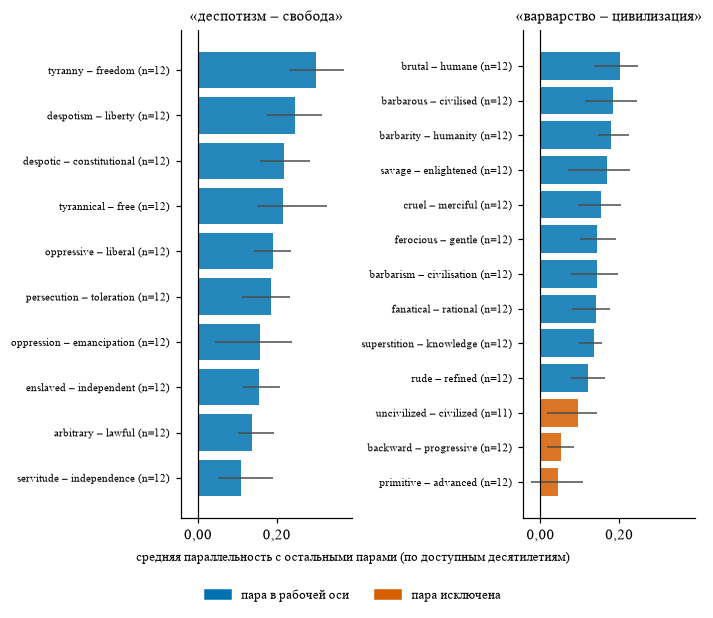

Сохранено: results/figures/02_axes_pair_agreement.png


In [3]:
dropped = {ax: set(C.DROP_PAIRS.get(ax, [])) for ax in C.AXES}
fig, axes = T.figure(height_cm=13, nrows=1, ncols=2, layout="constrained", sharex=True)
for axp, axn in zip(axes, C.WORKING_AXES):
    spec = C.AXES[axn]
    pp = diagnostics[axn]
    stat = pd.DataFrame({"mean": pp.mean(axis=1), "min": pp.min(axis=1), "max": pp.max(axis=1), "n": pp.count(axis=1)}).sort_values("mean")
    is_drop = [tuple(lbl.split(" – ")) in dropped[axn] for lbl in stat.index]
    colors = [C.PALETTE["red"] if d else C.PALETTE["blue"] for d in is_drop]
    y = np.arange(len(stat))
    axp.barh(y, stat["mean"], color=colors, alpha=0.85)
    axp.hlines(y, stat["min"], stat["max"], color="0.3", lw=1)
    axp.axvline(0, color="black", lw=0.8)
    axp.set_yticks(y, [f"{lbl} (n={int(k)})" for lbl,k in zip(stat.index,stat["n"])], fontsize=7)
    axp.set_title(f"«{spec['label']}»", fontsize=10)
    axp.xaxis.set_major_formatter(T.COMMA); axp.grid(axis="y", visible=False)
fig.supxlabel("средняя параллельность с остальными парами (по доступным десятилетиям)", fontsize=8.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=C.PALETTE["blue"]), plt.Rectangle((0, 0), 1, 1, color=C.PALETTE["red"])]
fig.legend(handles, ["пара в рабочей оси", "пара исключена"], loc="lower center", ncol=2, frameon=False,
           fontsize=8.5, bbox_to_anchor=(0.5, -0.08))
plt.show(); T.save_fig(fig, "02_axes_pair_agreement")

### Наглядно: направления пар (рисунок а)

Каждая пара изображена стрелкой от отрицательного слова к положительному. По горизонтали отложено положение слов на итоговой оси, по вертикали — второе направление, вдоль которого слова пар сильнее всего различаются. Если пары выражают одно противопоставление, стрелки направлены примерно в одну сторону, слева направо. Пространство модели 200-мерное, поэтому рисунок — упрощённая проекция и служит иллюстрацией. Показано десятилетие `DEC_SHOW`.

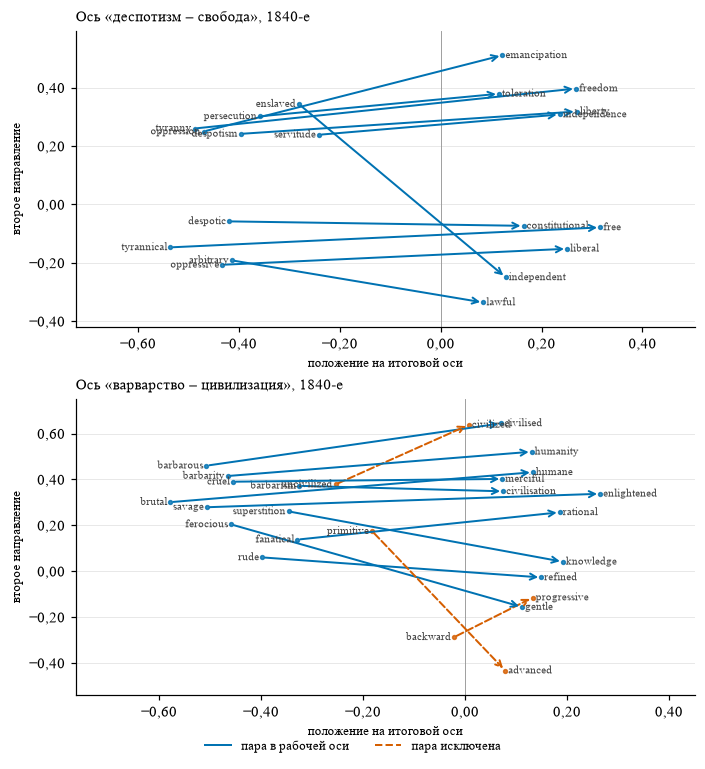

Сохранено: results/figures/02_axes_pair_arrows.png


In [4]:
DEC_SHOW = "1840s"   # десятилетие для иллюстрации; можно заменить

def pair_plane(Vp, all_pairs, axis):
    """Координаты слов пар на плоскости: (проекция на ось, первая главная компонента остатка)."""
    words = sorted({w for pr in all_pairs for w in pr})
    M = np.array([Vp[w] for w in words])
    R = M - np.outer(M @ axis, axis)
    R = R - R.mean(axis=0)
    u = np.linalg.svd(R, full_matrices=False)[2][0]
    return {w: (Vp[w] @ axis, Vp[w] @ u) for w in words}

Vp = V[DEC_SHOW]
fig, axes = T.figure(height_cm=17, nrows=2, ncols=1, layout="constrained")
for axp, axn in zip(axes, C.WORKING_AXES):
    spec = C.AXES[axn]
    a = T.axis_vector(Vp, C.working_pairs(axn))
    available = T.available_pairs(Vp, spec["pairs"])
    xy = pair_plane(Vp, available, a)
    for neg, pos in available:
        drop = (neg, pos) in dropped[axn]
        col = C.PALETTE["red"] if drop else C.PALETTE["blue"]
        (x0, y0), (x1, y1) = xy[neg], xy[pos]
        axp.annotate("", xy=(x1, y1), xytext=(x0, y0),
                     arrowprops=dict(arrowstyle="->", color=col, lw=1.3, ls="--" if drop else "-"))
        axp.plot([x0, x1], [y0, y1], "o", color=col, ms=2.5, alpha=0.8)
        axp.text(x0, y0, neg + " ", fontsize=7, color="0.25", ha="right", va="center", clip_on=True)
        axp.text(x1, y1, " " + pos, fontsize=7, color="0.25", ha="left", va="center", clip_on=True)
    axp.axvline(0, color="0.6", lw=0.6)
    axp.set_title(f"Ось «{spec['label']}», {T.decade_labels([DEC_SHOW])[0]}", fontsize=10, loc="left")
    axp.set_xlabel("положение на итоговой оси", fontsize=8.5)
    axp.set_ylabel("второе направление", fontsize=8.5)
    axp.xaxis.set_major_formatter(T.COMMA); axp.yaxis.set_major_formatter(T.COMMA)
    axp.margins(x=0.22, y=0.10)
handles = [plt.Line2D([], [], color=C.PALETTE["blue"], lw=1.3), plt.Line2D([], [], color=C.PALETTE["red"], lw=1.3, ls="--")]
fig.legend(handles, ["пара в рабочей оси", "пара исключена"], loc="lower center", ncol=2, frameon=False,
           fontsize=8.5, bbox_to_anchor=(0.5, -0.03))
plt.show(); T.save_fig(fig, "02_axes_pair_arrows")

### Согласованность рабочих осей

Средняя попарная параллельность фиксированных рабочих пар в каждом десятилетии. Диагностическая ось «восток — запад» рассчитывается только при наличии всех её пар.

In [5]:
rows = []
for ax in C.AXES:
    pairs = C.working_pairs(ax)
    for p, lab in zip(C.PERIODS, LABS):
        rows.append({"ось": C.AXES[ax]["label"], "пар": len(pairs), "десятилетие": lab,
                     "параллельность": round(T.parallelism(V[p], pairs), 4) if len(T.available_pairs(V[p],pairs)) == len(pairs) else np.nan})
rel = pd.DataFrame(rows)
display(rel.pivot(index="десятилетие", columns="ось", values="параллельность"))
display(rel.groupby("ось").agg(пар=("пар", "first"),
                                параллельность_мин=("параллельность", "min"),
                                параллельность_макс=("параллельность", "max")))
T.save_table(rel, "02_axes_reliability", index=False)

ось,варварство – цивилизация,восток – запад,деспотизм – свобода
десятилетие,,,
1800-е,0.1613,0.0425,0.2105
1810-е,0.2137,0.0630,0.2183
1820-е,0.2223,0.0284,0.2335
1830-е,0.2093,0.0407,0.2133
1840-е,0.2016,0.0959,0.2425
1850-е,0.1964,0.1106,0.1872
1860-е,0.2092,0.1472,0.2167
1870-е,0.1752,0.1535,0.1502
1880-е,0.1612,0.0796,0.1439


,пар,параллельность_мин,параллельность_макс
ось,,,
варварство – цивилизация,10,0.1337,0.2223
восток – запад,3,0.0284,0.1535
деспотизм – свобода,10,0.1439,0.2425


Сохранено: results/tables/02_axes_reliability.csv


## Положение России относительно других стран

Проекции одиннадцати названий стран на рабочие оси рассчитываются внутри модели каждого десятилетия. Ниже приведены проекции, место России среди одиннадцати названий и страны, занимающие первое и последнее места.

In [6]:
proj = {}
for axn in C.WORKING_AXES:
    pairs = C.working_pairs(axn)
    proj[axn] = pd.DataFrame({lab: {w: V[p][w] @ T.axis_vector(V[p], pairs) for w in C.COUNTRIES}
                              for p, lab in zip(C.PERIODS, LABS)}).T
    T.save_table(proj[axn].round(4), f"05_projections_{axn}")
    order = pd.DataFrame({"место России (1 = ниже всех)": proj[axn].rank(axis=1)[C.RUSSIA],
                          "последняя": proj[axn].idxmin(axis=1).map(C.COUNTRY_LABELS),
                          "первая": proj[axn].idxmax(axis=1).map(C.COUNTRY_LABELS)})
    print(f"Ось «{C.AXES[axn]['label']}»"); display(order.T)
    T.save_table(order, f"05_order_{axn}")
    first_uk = order["первая"].isin(["Британия", "Англия"]).sum()
    print(f"Британия или Англия на первом месте: {first_uk} из {len(order)} десятилетий")

Сохранено: results/tables/05_projections_liberty.csv
Ось «деспотизм – свобода»


,1800-е,1810-е,1820-е,1830-е,1840-е,1850-е,1860-е,1870-е,1880-е,1890-е,1900-е,1910-е
место России (1 = ниже всех),5.0,1.0,7.0,1.0,2.0,5.0,1.0,4.0,1.0,2.0,1.0,4.0
последняя,Франция,Россия,Италия,Россия,Испания,Италия,Россия,Турция,Россия,Австрия,Россия,Пруссия
первая,Британия,Америка,Британия,Британия,Британия,Британия,Британия,Америка,Англия,Британия,Британия,Англия


Сохранено: results/tables/05_order_liberty.csv
Британия или Англия на первом месте: 10 из 12 десятилетий
Сохранено: results/tables/05_projections_civilisation.csv
Ось «варварство – цивилизация»


,1800-е,1810-е,1820-е,1830-е,1840-е,1850-е,1860-е,1870-е,1880-е,1890-е,1900-е,1910-е
место России (1 = ниже всех),10.0,9.0,5.0,3.0,1.0,2.0,3.0,6.0,1.0,4.0,4.0,6.0
последняя,Испания,Испания,Италия,Турция,Россия,Испания,Турция,Турция,Россия,Турция,Испания,Пруссия
первая,Британия,Британия,Британия,Британия,Германия,Британия,Англия,Англия,Британия,Британия,Британия,Британия


Сохранено: results/tables/05_order_civilisation.csv
Британия или Англия на первом месте: 11 из 12 десятилетий


### Наглядно: страны на осях в одном десятилетии (рисунок в)

Одиннадцать названий стран отложены на шкалах «деспотизм – свобода» и «варварство – цивилизация» для десятилетия `DEC_SHOW`. Положение на шкале — проекция слова на ось. Россия и Британия выделены.

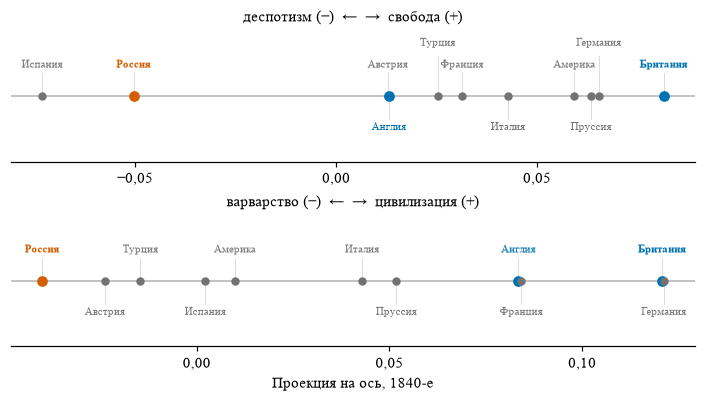

Сохранено: results/figures/02_countries_on_axes.png


In [7]:
from matplotlib.ticker import MaxNLocator
fig, axes = T.figure(height_cm=9, nrows=2, ncols=1, layout="constrained")
LEVELS = [0.5, -0.5, 0.85, -0.85]
for axp, axn in zip(axes, C.WORKING_AXES):
    vals = proj[axn].loc[T.decade_labels([DEC_SHOW])[0]].sort_values()
    span = vals.max() - vals.min()
    placed = []   # (x, уровень) уже размещённых подписей
    axp.axhline(0, color="0.7", lw=1)
    for w, v in vals.items():
        main = w in ("russia", "britain", "england")
        col = C.PALETTE["red"] if w == "russia" else (C.PALETTE["blue"] if w in ("britain", "england") else "0.45")
        axp.plot(v, 0, "o", color=col, ms=6 if main else 4.5, zorder=3)
        level = next((h for h in LEVELS if all(abs(v - x) > 0.11 * span or h != lev for x, lev in placed)), LEVELS[-1])
        placed.append((v, level))
        axp.plot([v, v], [0, level * 0.75], color="0.85", lw=0.6, zorder=1)
        axp.text(v, level, C.COUNTRY_LABELS[w], ha="center", va="center", fontsize=7.5, color=col,
                 fontweight="bold" if w in ("russia", "britain") else "normal")
    neg, pos = C.AXES[axn]["label"].split(" – ")
    axp.set_ylim(-1.05, 1.05); axp.set_yticks([])
    axp.set_title(f"{neg} (−)  ←  →  {pos} (+)", fontsize=9.5)
    axp.xaxis.set_major_locator(MaxNLocator(nbins=7, steps=[1, 2, 5, 10]))
    axp.xaxis.set_major_formatter(T.COMMA); axp.grid(False)
    for side in ("left", "right", "top"): axp.spines[side].set_visible(False)
axes[-1].set_xlabel(f"Проекция на ось, {T.decade_labels([DEC_SHOW])[0]}")
plt.show(); T.save_fig(fig, "02_countries_on_axes")

## Россия минус среднее по другим странам

Основной сравнительный показатель — разность между проекцией *russia* и средней проекцией десяти других названий стран. Отрицательная разность означает, что Россия ближе к полюсу деспотизма или варварства, чем другие страны в среднем.

In [8]:
rows = []
for axn in C.WORKING_AXES:
    pairs = C.working_pairs(axn)
    for p, lab in zip(C.PERIODS, LABS):
        rows.append({"ось": axn, "десятилетие": lab,
                     "разность": T.difference_from_controls(V[p], pairs, C.RUSSIA, controls)})
diff = pd.DataFrame(rows)
display(diff.pivot(index="десятилетие", columns="ось", values="разность").round(3))
T.save_table(diff.round(4), "05_russia_minus_others", index=False)

ось,civilisation,liberty
десятилетие,,
1800-е,0.070,-0.014
1810-е,0.038,-0.067
1820-е,-0.007,0.010
1830-е,-0.058,-0.065
1840-е,-0.088,-0.083
1850-е,-0.064,-0.028
1860-е,-0.048,-0.113
1870-е,0.004,-0.037
1880-е,-0.113,-0.097


Сохранено: results/tables/05_russia_minus_others.csv


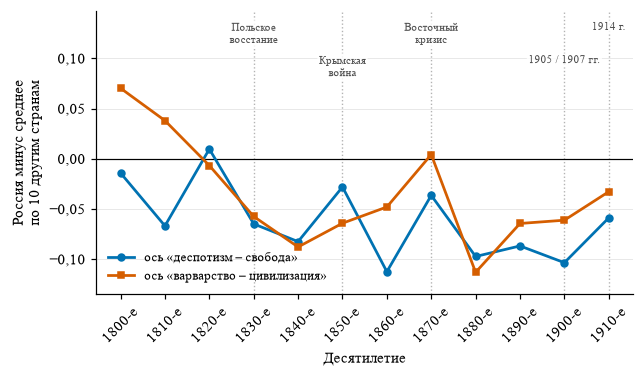

Сохранено: results/figures/fig2_russia_axes.png


In [9]:
fig, ax = T.figure(height_cm=8.5)
ax.axhline(0, color="black", lw=0.8)
style = {"liberty": (C.PALETTE["blue"], "o"), "civilisation": (C.PALETTE["red"], "s")}
for axn in C.WORKING_AXES:
    s = diff[diff["ось"] == axn]; col, mk = style[axn]
    ax.plot(x, s["разность"], color=col, marker=mk, ms=4.5, lw=1.8, label=f"ось «{C.AXES[axn]['label']}»")
lo = min(0, diff["разность"].min()); hi = max(0, diff["разность"].max())
span = max(hi - lo, 0.05)
for i, (p, text) in enumerate(C.EVENTS.items()):
    xi = C.PERIODS.index(p)
    ax.axvline(xi, color="0.7", ls=":", lw=0.9, zorder=0)
    ax.annotate(text, (xi, hi + span * (0.36 if i % 2 == 0 else 0.18)), ha="center", va="top", fontsize=7.5, color="0.3",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax.set_ylim(lo - 0.12 * span, hi + 0.42 * span); ax.yaxis.set_major_formatter(T.COMMA)
ax.set_xticks(x, LABS, rotation=45); ax.set_xlabel("Десятилетие")
ax.set_ylabel("Россия минус среднее\nпо 10 другим странам")
ax.legend(frameon=False, loc="lower left", fontsize=8.5)
plt.show(); T.save_fig(fig, "fig2_russia_axes")

## Россия среди других стран на оси «деспотизм – свобода» (рис. 3)

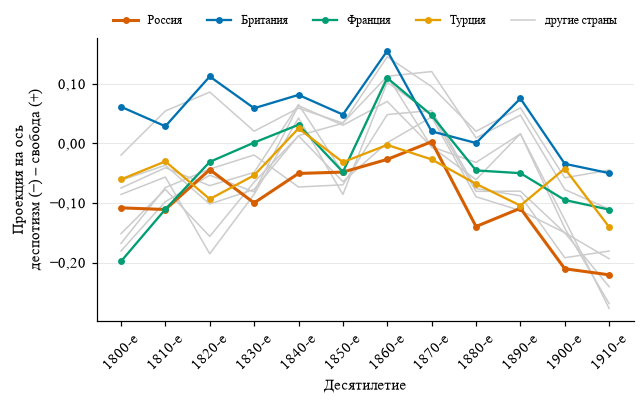

Сохранено: results/figures/fig3_countries_liberty.png


In [10]:
fig, ax = T.figure(height_cm=8.5)
highlight = {"russia": "red", "britain": "blue", "france": "green", "turkey": "orange"}
for w in C.COUNTRIES:
    if w not in highlight:
        ax.plot(x, proj["liberty"][w], color="0.8", lw=1)
for w, c in highlight.items():
    ax.plot(x, proj["liberty"][w], color=C.PALETTE[c], lw=2 if w == "russia" else 1.5, marker="o", ms=3.5, label=C.COUNTRY_LABELS[w])
ax.plot([], [], color="0.8", lw=1, label="другие страны")
ax.yaxis.set_major_formatter(T.COMMA); ax.set_xticks(x, LABS, rotation=45)
ax.set_xlabel("Десятилетие"); ax.set_ylabel("Проекция на ось\nдеспотизм (−) – свобода (+)")
ax.legend(frameon=False, ncol=5, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.show(); T.save_fig(fig, "fig3_countries_liberty")

## Чувствительность к опорным парам

Для каждой рабочей оси последовательно исключается одна из десяти пар. На оси из девяти пар вновь вычисляются проекция России, средняя проекция остальных названий, их разность и разрыв Британия–Россия. Сравниваем с полной осью, сохраняем все варианты, минимум и максимум и число смен знака (без округления). Это анализ чувствительности, а не доверительный интервал и не процедура подбора наиболее удобных пар.

Сохранено: results/tables/05_leave_one_pair_out.csv
Сохранено: results/tables/05_leave_one_pair_summary.csv


,ось,десятилетие,полная_разность,минимум,максимум,смены_знака,полный_разрыв,минимум_разрыва,максимум_разрыва,смены_знака_разрыва
0,liberty,1800-е,-0.0142,-0.0356,-0.0004,0,0.1697,0.1509,0.1847,0
1,liberty,1810-е,-0.0669,-0.0818,-0.0513,0,0.1398,0.1229,0.1693,0
2,liberty,1820-е,0.0096,-0.0051,0.0283,1,0.1564,0.1327,0.1761,0
3,liberty,1830-е,-0.0649,-0.0773,-0.0530,0,0.1590,0.1405,0.1737,0
4,liberty,1840-е,-0.0826,-0.0950,-0.0708,0,0.1319,0.1069,0.1534,0
5,liberty,1850-е,-0.0281,-0.0482,-0.0064,0,0.0966,0.0722,0.1298,0
6,liberty,1860-е,-0.1125,-0.1185,-0.1056,0,0.1823,0.1617,0.1982,0
7,liberty,1870-е,-0.0365,-0.0529,-0.0169,0,0.0173,-0.0131,0.0341,3
8,liberty,1880-е,-0.0974,-0.1135,-0.0825,0,0.1402,0.1181,0.1674,0
9,liberty,1890-е,-0.0869,-0.1032,-0.0660,0,0.1843,0.1657,0.2029,0


Сохранено: results/figures/05_axis_pair_sensitivity.png


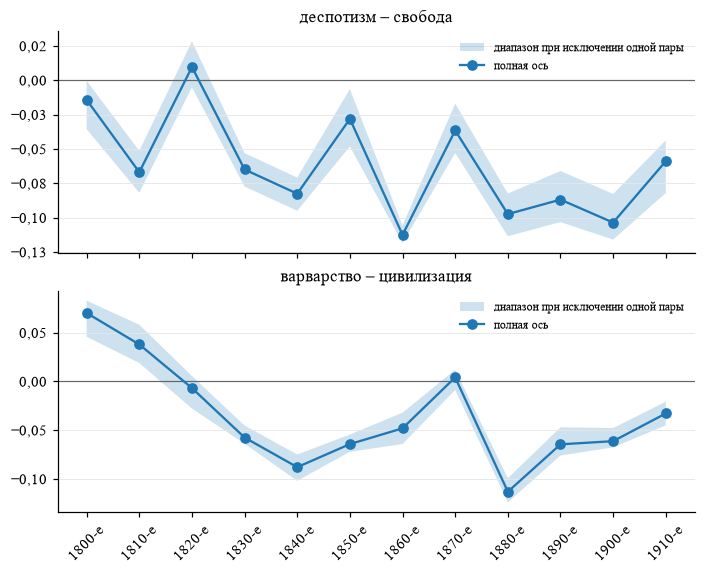

In [11]:
loo_rows = []
for axn in C.WORKING_AXES:
    pairs = C.working_pairs(axn)
    for p, lab in zip(C.PERIODS, LABS):
        vp = V[p]
        full = T.axis_vector(vp,pairs)
        full_diff = float(vp[C.RUSSIA] @ full - np.mean([vp[c] @ full for c in controls]))
        full_gap = float((vp["britain"]-vp[C.RUSSIA]) @ full)
        for omitted in pairs:
            axis = T.axis_vector(vp, [pair for pair in pairs if pair != omitted])
            scores = {w:float(vp[w]@axis) for w in C.COUNTRIES}
            control_mean = np.mean([scores[w] for w in controls])
            value = scores[C.RUSSIA]-control_mean
            gap = scores["britain"]-scores[C.RUSSIA]
            loo_rows.append({"ось":axn,"десятилетие":lab,"исключена_пара":" – ".join(omitted),
                             "russia":scores[C.RUSSIA],"среднее_других":control_mean,"разность":value,
                             "полная_разность":full_diff,"изменение":value-full_diff,
                             "britain_minus_russia":gap,"полный_разрыв":full_gap,
                             "смена_знака":np.sign(value)!=np.sign(full_diff),
                             "смена_знака_разрыва":np.sign(gap)!=np.sign(full_gap)})
loo = pd.DataFrame(loo_rows)
T.save_table(loo.round(6),"05_leave_one_pair_out",index=False)
summary = loo.groupby(["ось","десятилетие"],sort=False).agg(полная_разность=("полная_разность","first"),
    минимум=("разность","min"), максимум=("разность","max"), смены_знака=("смена_знака","sum"),
    полный_разрыв=("полный_разрыв","first"), минимум_разрыва=("britain_minus_russia","min"),
    максимум_разрыва=("britain_minus_russia","max"), смены_знака_разрыва=("смена_знака_разрыва","sum")).reset_index()
T.save_table(summary.round(6),"05_leave_one_pair_summary",index=False)
display(summary.round(4))
fig, axes = T.figure(height_cm=13,nrows=2,ncols=1,layout="constrained",sharex=True)
for axp,axn in zip(axes,C.WORKING_AXES):
    sub=summary[summary["ось"]==axn].set_index("десятилетие").reindex(LABS)
    axp.axhline(0,color="0.4",lw=.8)
    axp.fill_between(x,sub["минимум"].to_numpy(float),sub["максимум"].to_numpy(float),alpha=.22,label="диапазон при исключении одной пары")
    axp.plot(x,sub["полная_разность"],marker="o",label="полная ось")
    axp.set_title(C.AXES[axn]["label"]); axp.yaxis.set_major_formatter(T.COMMA); axp.legend(frameon=False,fontsize=8)
axes[-1].set_xticks(x,LABS,rotation=45)
T.save_fig(fig,"05_axis_pair_sensitivity"); plt.show()

## Чувствительность к сравнительной группе и сопоставление Британии с Россией

Основной набор неизменен. Дополнительные сценарии: исключение Турции; Германии и Пруссии; Англии и Пруссии (уменьшение веса пересекающихся обозначений). Кроме того, исключаем по одному каждое контрольное название. Все сценарии вычисляются для всех десятилетий; для исторической интерпретации особенно интересны 1870-е и 1910-е. Сравнительная разность зависит от всех названий, а не только от России. Разрыв *britain – russia* не зависит от контрольной группы.

Сохранено: results/tables/05_country_group_sensitivity.csv
Сохранено: results/tables/05_britain_russia.csv


,ось,десятилетие,сценарий,исключены,n_контрольных,russia,среднее_других,разность,изменение_к_основному
98,liberty,1870-е,основной,,10,0.0029,0.0394,-0.0365,0.0000
99,liberty,1870-е,без Турции,turkey,9,0.0029,0.0468,-0.0439,-0.0074
100,liberty,1870-е,без Германии и Пруссии,"germany, prussia",8,0.0029,0.0507,-0.0478,-0.0113
101,liberty,1870-е,без Англии и Пруссии,"england, prussia",8,0.0029,0.0381,-0.0352,0.0013
154,liberty,1910-е,основной,,10,-0.2207,-0.1618,-0.0589,0.0000
155,liberty,1910-е,без Турции,turkey,9,-0.2207,-0.1641,-0.0565,0.0024
156,liberty,1910-е,без Германии и Пруссии,"germany, prussia",8,-0.2207,-0.1339,-0.0867,-0.0278
157,liberty,1910-е,без Англии и Пруссии,"england, prussia",8,-0.2207,-0.1620,-0.0587,0.0002
266,civilisation,1870-е,основной,,10,-0.0193,-0.0235,0.0041,0.0000
267,civilisation,1870-е,без Турции,turkey,9,-0.0193,-0.0148,-0.0046,-0.0087


Сохранено: results/figures/05_britain_russia.png


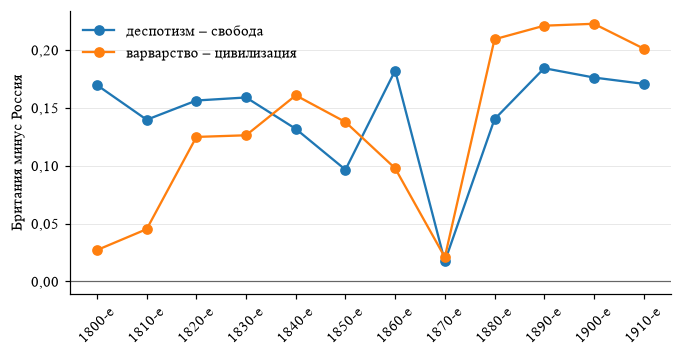

In [12]:
group_rows=[]; gap_rows=[]
scenarios = {"основной": [], **C.CONTROL_EXCLUSIONS, **{f"без {w}":[w] for w in controls}}
for axn in C.WORKING_AXES:
    for lab in LABS:
        row = proj[axn].loc[lab]
        original = float(row[C.RUSSIA]-row[controls].mean())
        gap_rows.append({"ось":axn,"десятилетие":lab,"britain":row["britain"],"russia":row[C.RUSSIA],
                         "britain_minus_russia":row["britain"]-row[C.RUSSIA]})
        for name, excluded in scenarios.items():
            keep=[w for w in controls if w not in excluded]
            mean=float(row[keep].mean()); value=float(row[C.RUSSIA]-mean)
            group_rows.append({"ось":axn,"десятилетие":lab,"сценарий":name,"исключены":", ".join(excluded),
                               "n_контрольных":len(keep),"russia":row[C.RUSSIA],"среднее_других":mean,
                               "разность":value,"изменение_к_основному":value-original})
groups=pd.DataFrame(group_rows); gaps=pd.DataFrame(gap_rows)
T.save_table(groups.round(6),"05_country_group_sensitivity",index=False)
T.save_table(gaps.round(6),"05_britain_russia",index=False)
display(groups[groups["десятилетие"].isin(["1870-е","1910-е"]) & groups["сценарий"].isin(["основной"]+list(C.CONTROL_EXCLUSIONS))].round(4))
fig,ax=T.figure(height_cm=8.5)
for axn in C.WORKING_AXES:
    sub=gaps[gaps["ось"]==axn].set_index("десятилетие").reindex(LABS)
    ax.plot(x,sub["britain_minus_russia"],marker="o",label=C.AXES[axn]["label"])
ax.axhline(0,color="0.4",lw=.8); ax.set_xticks(x,LABS,rotation=45)
ax.set_ylabel("Британия минус Россия"); ax.yaxis.set_major_formatter(T.COMMA); ax.legend(frameon=False)
fig.tight_layout(); T.save_fig(fig,"05_britain_russia"); plt.show()